# RoBERTa Embeddings Analysis

Visualize embeddings, compute cosine similarity, and analyze clustering by label.

Two pooling strategies are compared throughout:
- **CLS** — uses the `<s>` token's hidden state as the embedding (standard baseline)
- **Rationale-weighted** — weighted mean of all token hidden states where each token's weight is the average score from human annotators in HateXplain. Tokens flagged as evidence for the hate/offensive label carry more influence on the final 768-dim vector.


In [7]:
import json
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from transformers import RobertaTokenizer, RobertaModel
import torch
# cosine_similarity measures the angle between embedding vectors (1 = identical direction)
from sklearn.metrics.pairwise import cosine_similarity
# t-SNE reduces 768-dim embeddings to 2D for scatter-plot visualization
from sklearn.manifold import TSNE
# UMAP is another dimensionality reduction method — often preserves global structure
# better than t-SNE, making it easier to see how clusters relate to each other
import umap
import matplotlib.pyplot as plt
from collections import defaultdict

In [8]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


In [9]:
# Load HateXplain data directly from JSONL — the notebook is self-contained
# and computes its own embeddings rather than relying on pre-saved files.

def load_hatexplain_data(file_path):
    data = []
    with open(file_path, 'r') as f:
        for line in f:
            data.append(json.loads(line))
    return data

def reconstruct_text(post_tokens):
    return ' '.join(post_tokens)

train_data = load_hatexplain_data('hatexplain/hatexplain_train.jsonl')
valid_data = load_hatexplain_data('hatexplain/hatexplain_validation.jsonl')
test_data  = load_hatexplain_data('hatexplain/hatexplain_test.jsonl')

print(f"Train: {len(train_data)}, Valid: {len(valid_data)}, Test: {len(test_data)}")
print(f"Sample: {reconstruct_text(train_data[0]['post_tokens'])}")


Train: 15383, Valid: 1922, Test: 1924
Sample: u really think i would not have been raped by feral hindu or muslim back in india or bangladesh and a neo nazi would rape me as well just to see me cry


In [10]:
# Load RoBERTa — this is the same model used in the classification notebooks
roberta_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
roberta_model     = RobertaModel.from_pretrained('roberta-base').to(DEVICE)
roberta_model.eval()
print("RoBERTa ready")


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 2080.34it/s, Materializing param=encoder.layer.11.output.dense.weight]              
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa ready


In [11]:
def get_roberta_embedding(text, tokenizer, model, device,
                          pooling='cls', rationale_scores=None):
    """Extract a 768-dim embedding from RoBERTa.

    Special tokens: <s> and </s>
    ----------------------------
    Before passing text to RoBERTa, the tokenizer automatically adds two
    special tokens that were present during pre-training:

      <s>   — "start of sequence" (also called the CLS token in RoBERTa).
              Always sits at position 0. After all transformer layers, this
              token has attended to every other token, so its hidden state
              is a compressed summary of the whole sequence. This is what
              pooling='cls' returns.

      </s>  — "end of sequence" (also called the SEP token in other models).
              Always sits at the last real position (before any [PAD] tokens).
              Signals to the model where the text ends. Its hidden state is
              not typically used for sentence-level tasks.

    So for "dirty muslims":
      Raw input  :  dirty  muslims
      After tokenizer:  <s>  dirty  mus  ##lims  </s>
      Token indices:     0     1     2      3      4

    Why we zero out <s> and </s> in rationale-weighted pooling:
      The annotators labelled *content* words — they had no concept of
      <s>/<s> when highlighting tokens. Giving those positions any weight
      would inject noise. Setting them to 0.0 means they contribute nothing
      to the weighted mean, and only the actual word tokens are averaged.

    Example
    -------
    Post : "I love everyone except those dirty muslims"
    Words:  [0]  [1]     [2]      [3]    [4]   [5]     [6]

    Annotators flagged only the last two words as evidence:
      rationale_scores = [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0]

    RoBERTa BPE tokenization — "muslims" splits into two subwords:
      <s>  I  love  everyone  except  those  dirty  mus  ##lims  </s>
       ↑                                                           ↑
     always                                                    always
     pos 0                                                   last pos

    Weight vector (each subword inherits its parent word's score,
    special tokens get 0):
      <s>=0.0  I=0.0  love=0.0  everyone=0.0  except=0.0  those=0.0
      dirty=1.0  mus=1.0  ##lims=1.0  </s>=0.0

    Weighted mean = (h_dirty + h_mus + h_##lims) / 3

    The resulting 768-dim vector is centred on the hateful tokens.
    CLS pooling would mix in signal from "I", "love", "everyone", etc.

    pooling='cls'
        Return the <s> token hidden state at position 0.

    pooling='rationale'
        Weighted mean of all token hidden states using annotator rationale
        scores as weights. Each word's score is expanded to its subwords
        (RoBERTa uses BPE, so one word may become multiple tokens).
        Special tokens <s> and </s> always get weight 0.
        Falls back to plain mean pooling when all scores are zero
        (e.g. normal-labelled samples whose annotators gave no rationale).
    """
    # max_length=512 is RoBERTa's hard architectural limit.
    # The model's positional embedding table has 514 slots; positions 0-1
    # are reserved internally, leaving 512 usable positions. Of those 512,
    # two are taken by <s> and </s>, so real content can be at most 510
    # subword tokens. HateXplain posts are almost always well under 100
    # tokens, so this limit is never hit in practice — but it must be set
    # to prevent a crash on any outlier sequence.
    inputs = tokenizer(text, return_tensors='pt', truncation=True,
                       max_length=512, padding=True)
    inputs_on_device = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs_on_device)

    hidden          = outputs.last_hidden_state   # (1, seq_len, 768)
    attention_mask  = inputs['attention_mask']

    if pooling == 'cls':
        return hidden[0, 0, :].cpu().numpy().flatten()

    # ── Rationale-weighted pooling ──────────────────────────────────────────
    # Expand word-level rationale scores to subword token-level scores
    words    = text.split()
    word_ids = []
    for word_idx, word in enumerate(words):
        n_sub = len(tokenizer.encode(word, add_special_tokens=False))
        word_ids.extend([word_idx] * n_sub)

    max_sub  = inputs['input_ids'].shape[1] - 2   # exclude <s> and </s>
    word_ids = word_ids[:max_sub]

    scores = (rationale_scores
              if rationale_scores and any(s > 0 for s in rationale_scores)
              else None)

    weights = [scores[w] if scores and w < len(scores) else 1.0
               for w in word_ids]

    seq_len      = inputs['input_ids'].shape[1]
    full_weights = ([0.0]        # <s> — always zero, not a content token
                    + weights
                    + [0.0] * (seq_len - len(weights) - 1))  # </s> + padding
    full_weights = full_weights[:seq_len]

    att           = attention_mask[0].float().to(device)
    weight_tensor = torch.tensor(full_weights, dtype=torch.float32).to(device) * att
    weight_sum    = weight_tensor.sum()

    if weight_sum == 0:
        # All weights zero → plain mean pool over real (non-padding) tokens
        mask = att.unsqueeze(-1)
        return ((hidden[0] * mask).sum(0) / mask.sum()).cpu().numpy().flatten()

    w = weight_tensor.unsqueeze(-1)
    return ((hidden[0] * w).sum(0) / weight_sum).cpu().numpy().flatten()


In [ ]:
def encode_dataset(data, tokenizer, model, device,
                   pooling='cls', sample_size=None):
    """Encode each sample as a 768-dim RoBERTa embedding.

    Returns a list of dicts with keys: embedding, label, rationale_scores.
    """
    if sample_size:
        data = data[:sample_size]

    results = []
    for item in tqdm(data, desc=f"Encoding ({pooling})"):
        tokens       = item['post_tokens']
        text         = reconstruct_text(tokens)
        labels       = item['annotators']['label']
        majority_lbl = max(set(labels), key=labels.count)

        rationales = item['rationales']
        valid_rationales = [r for r in rationales if len(r) == len(tokens)]
        if valid_rationales:
            rationale_scores = np.mean(valid_rationales, axis=0).tolist()
        else:
            rationale_scores = [0.0] * len(tokens)

        embedding = get_roberta_embedding(
            text, tokenizer, model, device,
            pooling=pooling,
            rationale_scores=rationale_scores,
        )

        results.append({
            'embedding':        embedding,
            'label':            majority_lbl,
            'rationale_scores': rationale_scores,
        })
    return results


In [13]:
# Encode train + test with both pooling strategies.
# Set SAMPLE_SIZE to a smaller number (e.g. 500) for faster experimentation.
SAMPLE_SIZE = None

print("=== CLS pooling ===")
train_cls = encode_dataset(train_data, roberta_tokenizer, roberta_model, DEVICE,
                           pooling='cls', sample_size=SAMPLE_SIZE)
test_cls  = encode_dataset(test_data,  roberta_tokenizer, roberta_model, DEVICE,
                           pooling='cls', sample_size=SAMPLE_SIZE)

print("\n=== Rationale-weighted pooling ===")
train_rat = encode_dataset(train_data, roberta_tokenizer, roberta_model, DEVICE,
                           pooling='rationale', sample_size=SAMPLE_SIZE)
test_rat  = encode_dataset(test_data,  roberta_tokenizer, roberta_model, DEVICE,
                           pooling='rationale', sample_size=SAMPLE_SIZE)

# Numpy arrays — y_train/y_test are identical for both strategies
X_train_cls = np.array([r['embedding'] for r in train_cls])
X_test_cls  = np.array([r['embedding'] for r in test_cls])
X_train_rat = np.array([r['embedding'] for r in train_rat])
X_test_rat  = np.array([r['embedding'] for r in test_rat])
y_train     = np.array([r['label']     for r in train_cls])
y_test      = np.array([r['label']     for r in test_cls])

print(f"\nX_train_cls shape : {X_train_cls.shape}")
print(f"X_train_rat shape : {X_train_rat.shape}")
print(f"Label distribution: {pd.Series(y_train).value_counts().to_dict()}")


=== CLS pooling ===


Encoding (cls):  13%|█▎        | 1997/15383 [01:04<07:12, 30.98it/s]


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

In [ ]:
LABEL_MAP = {0: 'hate', 1: 'offensive', 2: 'normal'}

print("=== Dataset Overview ===")
print(f"Training samples : {len(y_train)}")
print(f"Test samples     : {len(y_test)}")
print(f"Label distribution (train): {pd.Series([LABEL_MAP[y] for y in y_train]).value_counts().to_dict()}")
print(f"\nEmbedding shapes:")
print(f"  CLS       — train {X_train_cls.shape}, test {X_test_cls.shape}")
print(f"  Rationale — train {X_train_rat.shape}, test {X_test_rat.shape}")


=== Dataset Overview ===
Training samples: 15383
Label distribution: {'offensive': 6251, 'hate': 4748, 'normal': 4384}


In [ ]:
# Compute pairwise cosine similarity on the same random 500 samples for both strategies.
# Using identical indices means any differences reflect pooling alone, not sample selection.
SIM_SAMPLE = 500
np.random.seed(42)
indices      = np.random.choice(len(X_train_cls), SIM_SAMPLE, replace=False)
X_sample_cls = X_train_cls[indices]
X_sample_rat = X_train_rat[indices]
y_sample     = y_train[indices]

print(f"Computing cosine similarity on {SIM_SAMPLE} samples (both pooling modes)...")
cos_sim_cls = cosine_similarity(X_sample_cls)   # (500, 500)
cos_sim_rat = cosine_similarity(X_sample_rat)
print(f"Similarity matrix shape: {cos_sim_cls.shape}")


Computing cosine similarity on 500 samples...
Similarity matrix shape: (500, 500)


In [ ]:
# Group pairwise similarities by label-pair type and compare both strategies.
# High same-class similarity + low cross-class similarity = good class separation.
def analyze_similarity_by_label(y_sample, cos_sim_matrix):
    results = defaultdict(list)
    n = len(y_sample)
    for i in range(n):
        for j in range(i + 1, n):
            if y_sample[i] != y_sample[j]:
                pair_type = f"{LABEL_MAP[y_sample[i]]}-{LABEL_MAP[y_sample[j]]}"
            else:
                pair_type = f"same-{LABEL_MAP[y_sample[i]]}"
            results[pair_type].append(cos_sim_matrix[i, j])
    return results

sim_cls = analyze_similarity_by_label(y_sample, cos_sim_cls)
sim_rat = analyze_similarity_by_label(y_sample, cos_sim_rat)

print(f"{'Pair type':<25}  {'CLS mean':>10}  {'Rationale':>10}  {'Δ (rat−cls)':>12}")
print("-" * 62)
for pair in sorted(sim_cls.keys()):
    m_cls = np.mean(sim_cls[pair])
    m_rat = np.mean(sim_rat[pair])
    print(f"{pair:<25}  {m_cls:>10.4f}  {m_rat:>10.4f}  {m_rat - m_cls:>+12.4f}")


=== Cosine Similarity by Label Pairs ===
hate-normal: mean=0.9972, std=0.0006
hate-offensive: mean=0.9971, std=0.0007
normal-hate: mean=0.9972, std=0.0006
normal-offensive: mean=0.9970, std=0.0007
offensive-hate: mean=0.9971, std=0.0007
offensive-normal: mean=0.9971, std=0.0007
same-hate: mean=0.9973, std=0.0006
same-normal: mean=0.9972, std=0.0006
same-offensive: mean=0.9970, std=0.0007


In [ ]:
# Compute the centroid (mean embedding) for each class under both pooling strategies.
# The centroid represents the "average" position of a class in embedding space.
def compute_class_means(X, y):
    class_emb = defaultdict(list)
    for emb, label in zip(X, y):
        class_emb[label].append(emb)
    return {label: np.mean(embs, axis=0) for label, embs in class_emb.items()}

class_means_cls = compute_class_means(X_train_cls, y_train)
class_means_rat = compute_class_means(X_train_rat, y_train)

print("=== Samples per class ===")
for label in sorted(class_means_cls):
    print(f"  {LABEL_MAP[label]}: {np.sum(y_train == label)}")



=== Average Embedding per Class ===
normal: 4384 samples
offensive: 6251 samples
hate: 4748 samples


In [ ]:
# Compare inter-class centroid distances for both strategies.
# Lower centroid similarity = classes occupy more distinct regions.
print("=== Cosine Similarity Between Class Centroids ===\n")
print(f"{'Pair':<25}  {'CLS':>8}  {'Rationale':>10}  {'Δ (rat−cls)':>12}")
print("-" * 60)

labels_sorted = sorted(class_means_cls.keys())
for i in range(len(labels_sorted)):
    for j in range(i + 1, len(labels_sorted)):
        la, lb = labels_sorted[i], labels_sorted[j]
        sim_c = cosine_similarity([class_means_cls[la]], [class_means_cls[lb]])[0][0]
        sim_r = cosine_similarity([class_means_rat[la]], [class_means_rat[lb]])[0][0]
        pair  = f"{LABEL_MAP[la]} vs {LABEL_MAP[lb]}"
        print(f"{pair:<25}  {sim_c:>8.4f}  {sim_r:>10.4f}  {sim_r - sim_c:>+12.4f}")

print("\n(Lower centroid similarity = more distinct class regions in embedding space)")



=== Cosine Similarity Between Class Centroids ===
normal vs offensive: 1.0000
normal vs hate: 1.0000
offensive vs hate: 0.9999


In [ ]:
# Run t-SNE on both pooling strategies using the same random sample.
# Identical indices → any layout differences reflect the embeddings, not sampling.
print("Running t-SNE on both pooling strategies (this may take a couple of minutes)...")

TSNE_SAMPLE = 2000
np.random.seed(42)
tsne_idx   = np.random.choice(len(X_train_cls), min(TSNE_SAMPLE, len(X_train_cls)), replace=False)
X_tsne_cls = X_train_cls[tsne_idx]
X_tsne_rat = X_train_rat[tsne_idx]
y_tsne     = y_train[tsne_idx]

tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne_cls_2d = tsne.fit_transform(X_tsne_cls)
X_tsne_rat_2d = tsne.fit_transform(X_tsne_rat)
print("t-SNE complete!")


Running t-SNE (this may take a minute)...
t-SNE complete!


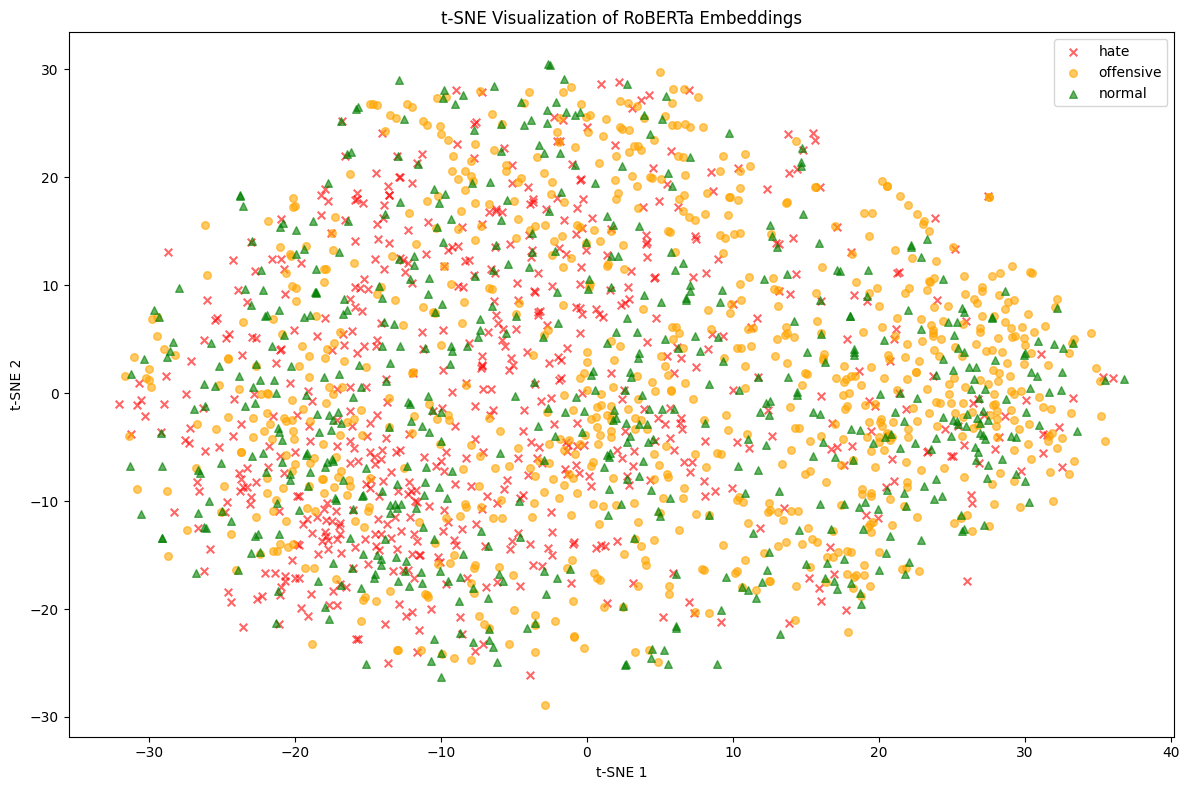

t-SNE plot saved to embeddings/tsne_visualization.png


In [ ]:
# Side-by-side t-SNE: CLS (left) vs rationale-weighted (right).
# Tighter, more separated clusters on the right = rationale pooling is more discriminative.
colors  = {'hate': 'red', 'offensive': 'orange', 'normal': 'green'}
markers = {'hate': 'x',   'offensive': 'o',       'normal': '^'}

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, X_2d, title in zip(
        axes,
        [X_tsne_cls_2d, X_tsne_rat_2d],
        ['CLS pooling', 'Rationale-weighted pooling']):
    for label in [0, 1, 2]:
        mask = y_tsne == label
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=colors[LABEL_MAP[label]], marker=markers[LABEL_MAP[label]],
                   label=LABEL_MAP[label], alpha=0.6, s=30)
    ax.set_title(f't-SNE — {title}', fontsize=14)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
    ax.legend()

plt.suptitle('t-SNE: CLS vs Rationale-Weighted Embeddings', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig('embeddings/tsne_cls_vs_rationale.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to embeddings/tsne_cls_vs_rationale.png")


## UMAP Visualization

**Why UMAP in addition to t-SNE?**
- t-SNE focuses on preserving *local* neighborhood structure but can distort global relationships — clusters may appear separated even when they aren't, or be positioned randomly relative to each other.
- UMAP better preserves *global* structure: if two classes are genuinely close in 768-dim space, they'll appear close in the 2D plot too.
- UMAP is also faster than t-SNE on large datasets.

Key UMAP parameters:
- `n_neighbors`: controls how local vs global the embedding is. Low values (5–15) emphasize local structure; higher values (30–50) reveal more global patterns.
- `min_dist`: how tightly points are packed. Lower values create tighter, more separated clusters.
- `metric`: distance function in the original space — cosine is natural for text embeddings since direction matters more than magnitude.

In [ ]:
# Run UMAP on both pooling strategies using the same sample as t-SNE.
# n_neighbors=30: balances local and global structure
# min_dist=0.3: moderate cluster packing
# metric='cosine': natural for text embeddings (direction matters more than magnitude)
print("Running UMAP on both pooling strategies...")
reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.3,
                    metric='cosine', random_state=42)
X_umap_cls_2d = reducer.fit_transform(X_tsne_cls)
X_umap_rat_2d = reducer.fit_transform(X_tsne_rat)
print("UMAP complete!")


Running UMAP...


/Users/shariff/Documents/github/11th-DAP-hate-speech/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP complete!


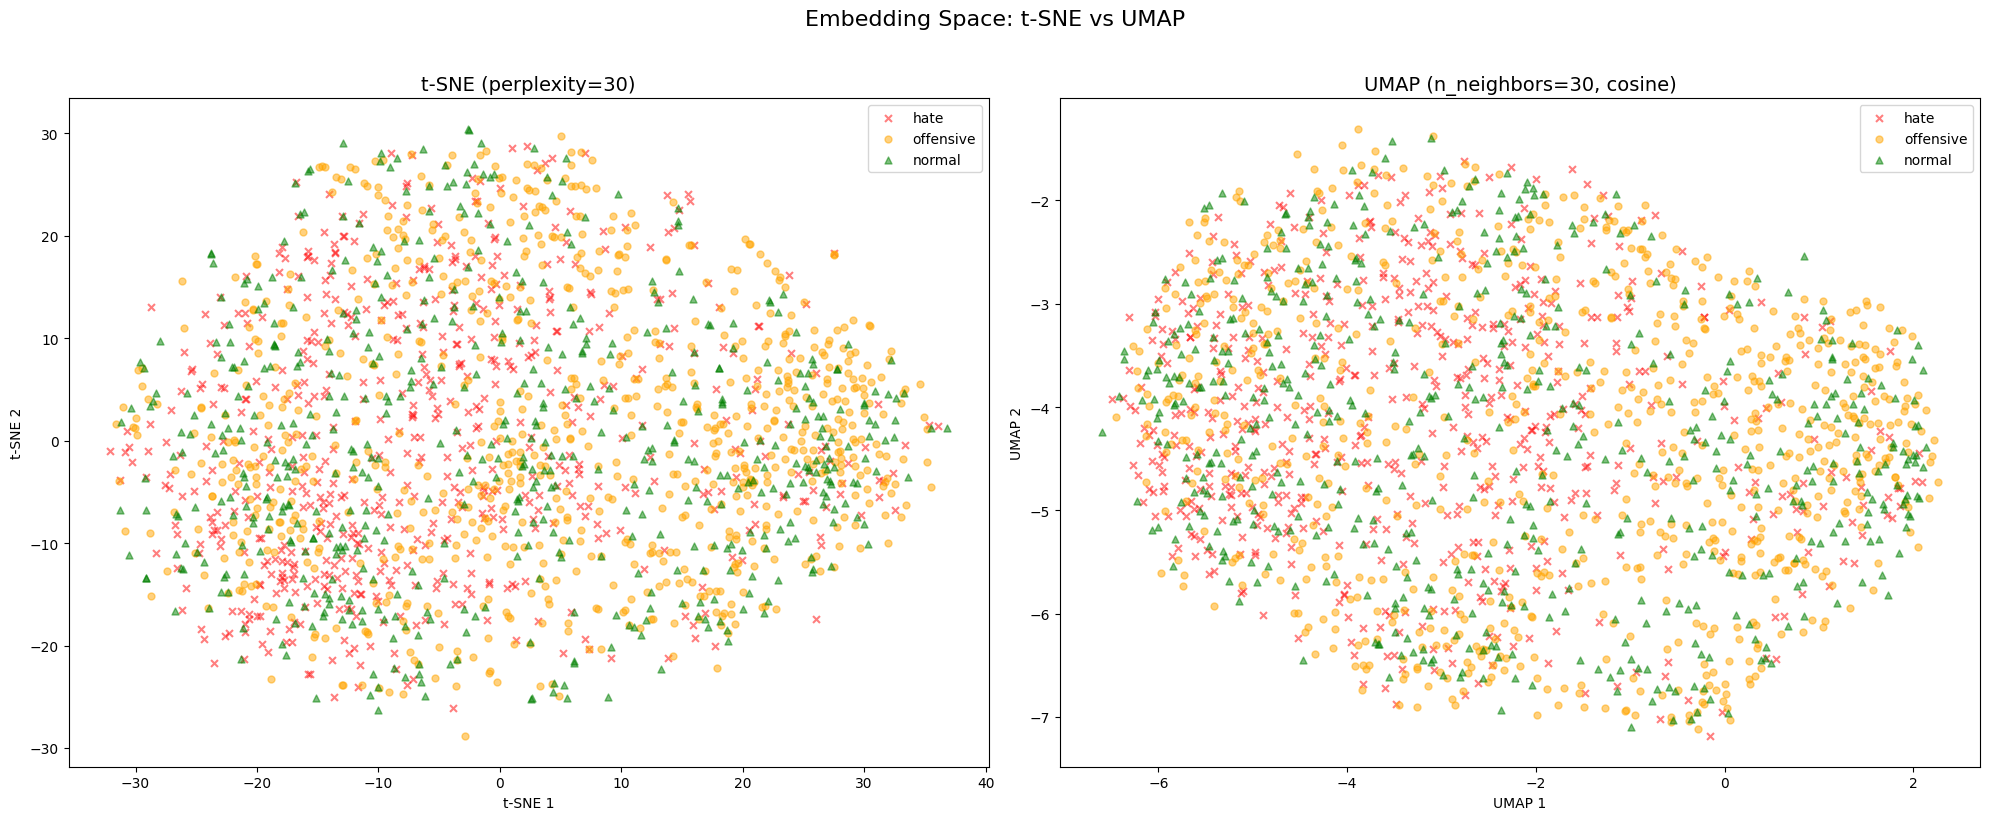

In [ ]:
# 2×2 comparison: rows = method (t-SNE / UMAP), columns = pooling (CLS / Rationale-weighted)
colors  = {'hate': 'red', 'offensive': 'orange', 'normal': 'green'}
markers = {'hate': 'x',   'offensive': 'o',       'normal': '^'}

fig, axes = plt.subplots(2, 2, figsize=(20, 16))

configs = [
    (0, 0, X_tsne_cls_2d, 't-SNE — CLS'),
    (0, 1, X_tsne_rat_2d, 't-SNE — Rationale-weighted'),
    (1, 0, X_umap_cls_2d, 'UMAP — CLS'),
    (1, 1, X_umap_rat_2d, 'UMAP — Rationale-weighted'),
]

for row, col, X_2d, title in configs:
    ax = axes[row][col]
    for label in [0, 1, 2]:
        mask = y_tsne == label
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1],
                   c=colors[LABEL_MAP[label]], marker=markers[LABEL_MAP[label]],
                   label=LABEL_MAP[label], alpha=0.5, s=25)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel('Dim 1')
    ax.set_ylabel('Dim 2')
    ax.legend(fontsize=9)

plt.suptitle('Embedding Space: t-SNE & UMAP × CLS & Rationale-Weighted', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('embeddings/tsne_umap_cls_vs_rationale.png', dpi=150, bbox_inches='tight')
plt.show()


/Users/shariff/Documents/github/11th-DAP-hate-speech/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shariff/Documents/github/11th-DAP-hate-speech/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/shariff/Documents/github/11th-DAP-hate-speech/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


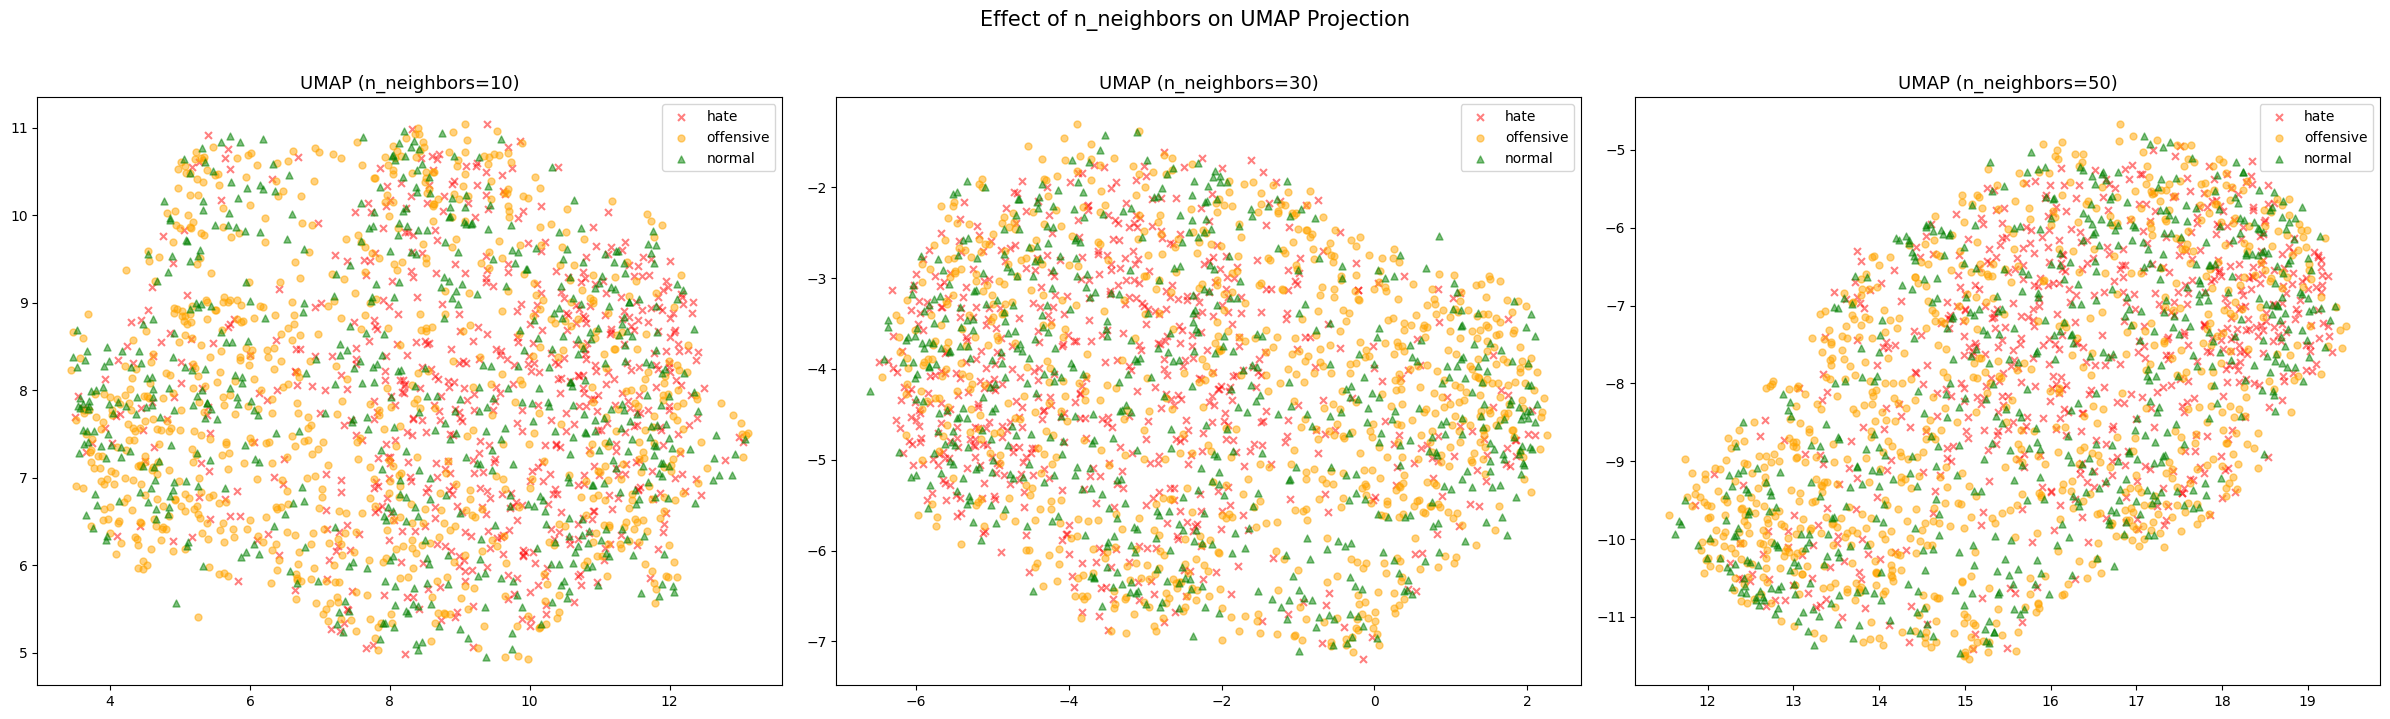

In [ ]:
# Effect of n_neighbors on UMAP (shown for rationale-weighted embeddings).
# Low n_neighbors (10) → emphasizes local micro-clusters
# High n_neighbors (50) → emphasizes global macro-structure
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

colors  = {'hate': 'red', 'offensive': 'orange', 'normal': 'green'}
markers = {'hate': 'x',   'offensive': 'o',       'normal': '^'}

for ax, nn in zip(axes, [10, 30, 50]):
    reducer_nn = umap.UMAP(n_components=2, n_neighbors=nn, min_dist=0.3,
                           metric='cosine', random_state=42)
    X_nn = reducer_nn.fit_transform(X_tsne_rat)
    for label in [0, 1, 2]:
        mask = y_tsne == label
        ax.scatter(X_nn[mask, 0], X_nn[mask, 1],
                   c=colors[LABEL_MAP[label]], marker=markers[LABEL_MAP[label]],
                   label=LABEL_MAP[label], alpha=0.5, s=25)
    ax.set_title(f'UMAP n_neighbors={nn} (rationale)', fontsize=13)
    ax.legend()

plt.suptitle('Effect of n_neighbors on UMAP (Rationale-Weighted Embeddings)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('embeddings/umap_n_neighbors_rationale.png', dpi=150, bbox_inches='tight')
plt.show()


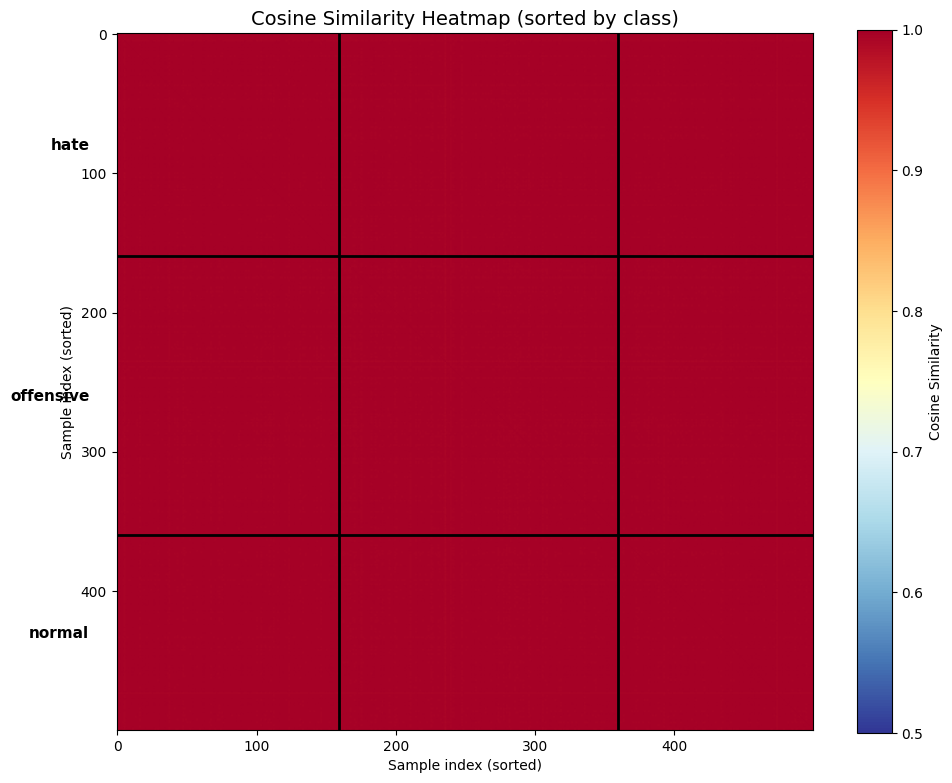

In [ ]:
# Side-by-side cosine similarity heatmaps: CLS vs rationale-weighted.
# Rows/columns are sorted by class so within-class blocks appear on the diagonal.
# Brighter diagonal blocks = tighter within-class clustering.
sorted_order = np.argsort(y_sample)
y_sorted     = y_sample[sorted_order]

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, sim_mat, title in zip(
        axes,
        [cos_sim_cls[sorted_order][:, sorted_order],
         cos_sim_rat[sorted_order][:, sorted_order]],
        ['CLS pooling', 'Rationale-weighted pooling']):

    im = ax.imshow(sim_mat, cmap='RdYlBu_r', vmin=0.5, vmax=1.0)
    plt.colorbar(im, ax=ax, label='Cosine Similarity')

    class_boundaries = [np.sum(y_sorted == lbl) for lbl in [0, 1, 2]]
    cumulative = np.cumsum(class_boundaries[:-1])
    for boundary in cumulative:
        ax.axhline(y=boundary - 0.5, color='black', linewidth=2)
        ax.axvline(x=boundary - 0.5, color='black', linewidth=2)

    positions = [0] + list(cumulative) + [len(y_sorted)]
    for i, lbl in enumerate([0, 1, 2]):
        mid = (positions[i] + positions[i + 1]) / 2
        ax.text(-20, mid, LABEL_MAP[lbl], fontsize=10, ha='right', va='center', fontweight='bold')

    ax.set_title(f'Cosine Similarity Heatmap — {title}', fontsize=13)
    ax.set_xlabel('Sample index (sorted by class)')
    ax.set_ylabel('Sample index (sorted by class)')

plt.suptitle('Cosine Similarity Heatmaps: CLS vs Rationale-Weighted', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('embeddings/cosine_heatmap_cls_vs_rationale.png', dpi=150, bbox_inches='tight')
plt.show()


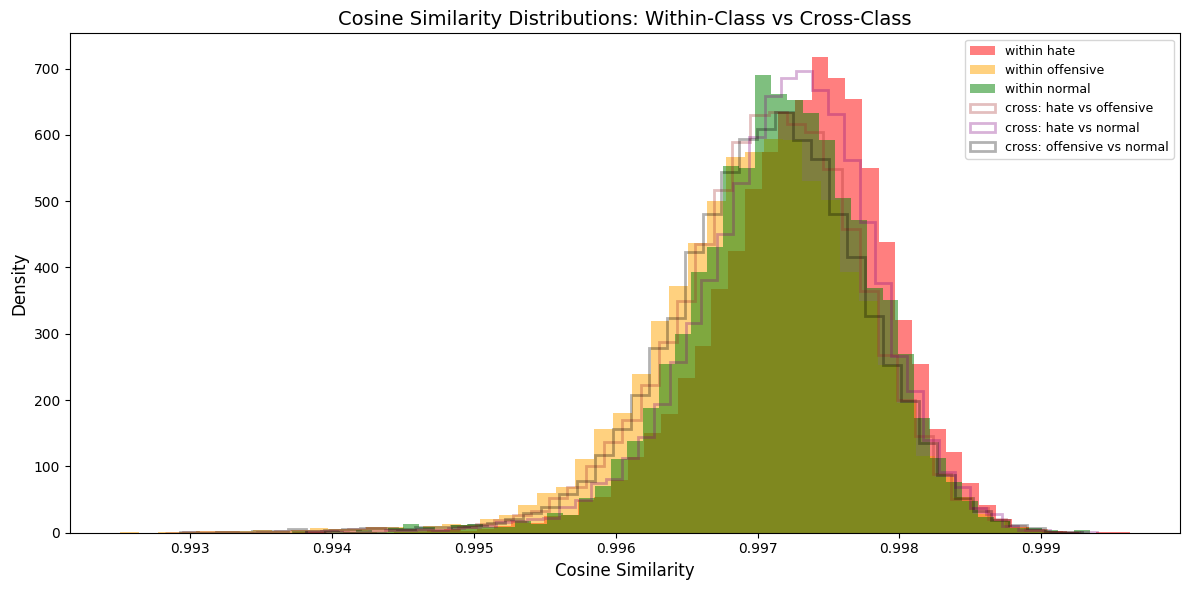

In [ ]:
# Side-by-side similarity distributions: CLS vs rationale-weighted.
# Within-class distributions (solid, coloured) should shift right vs cross-class (dashed)
# if the embedding space separates the classes well.
clr = {'hate': 'red', 'offensive': 'orange', 'normal': 'green'}
cross_colors = {'hate vs normal': 'purple', 'hate vs offensive': 'brown',
                'normal vs offensive': 'gray'}
# Canonical cross-pair names (normalize reverse-order keys)
cross_key_map = {
    'hate-normal':      'hate vs normal',
    'normal-hate':      'hate vs normal',
    'hate-offensive':   'hate vs offensive',
    'offensive-hate':   'hate vs offensive',
    'normal-offensive': 'normal vs offensive',
    'offensive-normal': 'normal vs offensive',
}

fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharey=True)
for ax, sim_results, title in zip(
        axes, [sim_cls, sim_rat],
        ['CLS pooling', 'Rationale-weighted pooling']):

    for label in [0, 1, 2]:
        key  = f'same-{LABEL_MAP[label]}'
        sims = sim_results.get(key, [])
        ax.hist(sims, bins=50, alpha=0.5, density=True,
                label=f'within {LABEL_MAP[label]}', color=clr[LABEL_MAP[label]])

    seen = set()
    for raw_key, sims in sim_results.items():
        if raw_key.startswith('same-'):
            continue
        disp = cross_key_map.get(raw_key, raw_key)
        if disp in seen:
            continue
        seen.add(disp)
        ax.hist(sims, bins=50, alpha=0.3, density=True, histtype='step', linewidth=2,
                label=f'cross: {disp}', color=cross_colors.get(disp, 'black'))

    ax.set_xlabel('Cosine Similarity', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'Similarity Distributions — {title}', fontsize=13)
    ax.legend(fontsize=8)

plt.suptitle('Within-Class vs Cross-Class Cosine Similarity', fontsize=15, y=1.02)
plt.tight_layout()
plt.savefig('embeddings/similarity_distributions_cls_vs_rationale.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# kNN purity: for each of 500 random training samples, what fraction of its
# 10 nearest neighbors share the same label? Run for both pooling strategies.
print("=== kNN Purity Analysis (k=10, 500 samples) ===\n")
print(f"{'Class':<12}  {'CLS mean':>10}  {'CLS std':>8}  {'Rat mean':>10}  {'Rat std':>8}")
print("-" * 55)

np.random.seed(42)
knn_idx = np.random.choice(len(X_train_cls), 500, replace=False)

cls_purity = {0: [], 1: [], 2: []}
rat_purity = {0: [], 1: [], 2: []}

for idx in knn_idx:
    for purity_dict, X_pool in [(cls_purity, X_train_cls), (rat_purity, X_train_rat)]:
        sims        = cosine_similarity(X_pool[idx].reshape(1, -1), X_pool)[0]
        sims[idx]   = -1
        top_10      = np.argsort(sims)[-10:]
        same        = np.sum(y_train[top_10] == y_train[idx])
        purity_dict[y_train[idx]].append(same / 10)

for label in [0, 1, 2]:
    print(f"{LABEL_MAP[label]:<12}  "
          f"{np.mean(cls_purity[label]):>10.3f}  {np.std(cls_purity[label]):>8.3f}  "
          f"{np.mean(rat_purity[label]):>10.3f}  {np.std(rat_purity[label]):>8.3f}")

cls_overall = np.mean([p for ps in cls_purity.values() for p in ps])
rat_overall = np.mean([p for ps in rat_purity.values() for p in ps])
print(f"\n{'Overall':<12}  {cls_overall:>10.3f}  {'':>8}  {rat_overall:>10.3f}")
print("\n(1.0 = all neighbors same class, 0.33 = random chance for 3 classes)")


=== kNN Purity Analysis (k=10, 500 random samples) ===

      hate: mean purity = 0.537, std = 0.221, n_samples = 160
 offensive: mean purity = 0.473, std = 0.239, n_samples = 200
    normal: mean purity = 0.361, std = 0.182, n_samples = 140

  Overall mean purity: 0.462
  (1.0 = all neighbors same class, 0.33 = random chance for 3 classes)


In [ ]:
# Silhouette score: how well does each sample fit its own cluster vs the nearest other?
# Range: -1 (wrong cluster) to +1 (perfect); 0 = overlapping clusters.
from sklearn.metrics import silhouette_score

print("=== Silhouette Scores ===\n")
sil_sample = 1000
np.random.seed(42)
sil_idx = np.random.choice(len(X_train_cls), sil_sample, replace=False)
y_sil   = y_train[sil_idx]

for X_pool, label in [(X_train_cls[sil_idx], 'CLS'),
                      (X_train_rat[sil_idx], 'Rationale-weighted')]:
    score = silhouette_score(X_pool, y_sil)
    print(f"  {label:<25}  Silhouette = {score:.4f}")

print("\n  (Range: -1 to +1, higher = better-separated clusters)")


=== Cluster Quality Metrics ===
Silhouette Score: -0.0028
  (Range: -1 to 1, higher = better cluster separation)


In [ ]:
# Summary: within-class variance comparison between pooling strategies.
# Lower within-class variance relative to overall variance means tighter clustering.
print("=== Summary ===\n")
print(f"Embedding dimension : {X_train_cls.shape[1]}")
print(f"Training samples    : {len(y_train)}")
print(f"Classes             : hate (0), offensive (1), normal (2)\n")

print("=== Within-Class Variance ===\n")
print(f"{'Class':<12}  {'CLS':>10}  {'Rationale':>12}  {'Δ (rat−cls)':>13}")
print("-" * 52)

for label in [0, 1, 2]:
    mask    = y_train == label
    var_cls = np.mean(np.var(X_train_cls[mask], axis=0))
    var_rat = np.mean(np.var(X_train_rat[mask], axis=0))
    print(f"{LABEL_MAP[label]:<12}  {var_cls:>10.4f}  {var_rat:>12.4f}  {var_rat - var_cls:>+13.4f}")

overall_cls = np.mean(np.var(X_train_cls, axis=0))
overall_rat = np.mean(np.var(X_train_rat, axis=0))
print(f"\n{'Overall':<12}  {overall_cls:>10.4f}  {overall_rat:>12.4f}  {overall_rat - overall_cls:>+13.4f}")
print("\n(Lower within-class variance relative to overall = tighter clustering)")



=== Summary ===
Embedding dimension: 768
Total training samples: 15383
Classes: hate (0), offensive (1), normal (2)

=== Variance Analysis ===
hate within-class variance: 0.0005
offensive within-class variance: 0.0005
normal within-class variance: 0.0005
Overall variance: 0.0005
